# dlt, from a hand-written loader to an incremental pipeline

Day 1, before Lab 1.3 · CPU only. Finance needs Qafila's payments in the warehouse every day, refunds included. You
load them with a short script, watch it go wrong in four ways, then let dlt do the same job and read every file and
table it produces, so nothing in Lab 1.3 is magic.

**The data:** a few invented payments (SAR), sent by a payment provider day by day, small enough to check by eye.
Lab 1.3 does the same with the real provider API and the app database.

🤔 asks you to predict before you run a cell · 🔍 says what the output means · ➕ sections are for your own pace.

**Contents**
- [ ] 1 · The problem: a loader written by hand
- [ ] 2 · The mental model: a resource, three steps, a load package
- [ ] 3 · Hello world, and the three steps one at a time
- [ ] 4 · Write dispositions: append, replace, merge
- [ ] 5 · Incremental loading: a cursor kept in state
- [ ] 6 · Break it on purpose: a late record slips past the cursor ➕
- [ ] 7 · Schemas: inferred, evolved, nested, and frozen by a contract
- [ ] 8 · From Python lists to a real API ➕
- [ ] 9 · Summary

🎓 **Instructor notes** (instructor copy only)

- Run the setup cell before class (Colab installs dlt in about a minute).
- Core ≈ 25' (estimated, not taught yet): §1 4' · §2 2' · §3 5' · §4 4' · §5 5' · §7 3' (evolution; nested,
  variant and contracts ➕) · §9 2'. §6 and §8 are ➕. Sections 1–5 carry the session: the pain, the three steps,
  dispositions, the cursor in state.
- In class, run the cells of a ➕ part without stopping on them: later cells may use what they build.
  Lab 1.3 repeats each of them on the real API, so don't solve the lab's exercises here.
- Ask every 🤔 question out loud and wait for two or three answers before running the cell.
- Expect "why not Airbyte / Fivetran?": same jobs (pagination, state, schema, load log), as a hosted service with
  ready-made connectors. dlt is a library: the pipeline is Python you can read, test and run anywhere.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "duckdb>=1.4", "dlt[duckdb]>=1.30"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # tools/ and solutions/tools/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import gzip
import re
import shutil

os.environ["RUNTIME__LOG_LEVEL"] = "ERROR"   # keep dlt's log quiet in the notebook
import dlt
import duckdb
import pandas as pd
from IPython.display import display
import de_utils as U
import de_viz as V

# Rerunning THIS cell starts again from an empty folder (it only deletes this notebook's own outputs).
OUT = U.lab_dir("tools_dlt", reset=True)
DB = OUT / "qafila_payments.duckdb"
PIPELINES = OUT / ".dlt"           # dlt's local working folder (by default it lives in ~/.dlt)
print("Output folder:", OUT)


def sql(query):
    # Each query opens and closes its own connection, so the file is free when dlt loads into it.
    with duckdb.connect(str(DB)) as connection:
        connection.execute("SET TimeZone = 'UTC'")   # show timestamps as the provider sends them
        return connection.sql(query).df()

Output folder: C:\Users\nayef\Desktop\courses\data-engineering\labs\artifacts\tools_dlt


dlt **ingests**: it reads from the sources on the left and lands their data, as sent, in the **bronze** zone, a
`raw` schema in DuckDB.

In [2]:
V.platform_map(tool="dlt")

The provider's feed. Each record is one version of a payment: when a payment changes (a refund), the provider sends
it again with a later `updated_at`. `provider(day, since)` returns that day's export: the latest version of every
payment, or only those changed `since` a time.

In [3]:
FEED = [
    # Monday 14 September
    {"payment_id": 9001, "order_id": 101, "amount": 275.86, "method": "card", "status": "captured",
     "updated_at": "2026-09-14T09:05:00Z"},
    {"payment_id": 9002, "order_id": 102, "amount": 33.65, "method": "wallet", "status": "captured",
     "updated_at": "2026-09-14T10:10:00Z"},
    {"payment_id": 9003, "order_id": 103, "amount": 12.00, "method": "card", "status": "captured",
     "updated_at": "2026-09-14T11:20:00Z"},
    # Tuesday: order 103 is refunded, and a new payment
    {"payment_id": 9003, "order_id": 103, "amount": 12.00, "method": "card", "status": "refunded",
     "updated_at": "2026-09-15T08:30:00Z"},
    {"payment_id": 9004, "order_id": 104, "amount": 58.10, "method": "card", "status": "captured",
     "updated_at": "2026-09-15T12:45:00Z"},
    # Wednesday: the provider starts sending `wallet_provider`
    {"payment_id": 9005, "order_id": 105, "amount": 19.90, "method": "wallet", "wallet_provider": "STC Pay",
     "status": "captured", "updated_at": "2026-09-16T09:15:00Z"},
    # Thursday: one payment from Wednesday morning reaches the export a day late
    {"payment_id": 9006, "order_id": 106, "amount": 44.00, "method": "card", "status": "captured",
     "updated_at": "2026-09-16T08:50:00Z", "_posted": "2026-09-17"},
    {"payment_id": 9007, "order_id": 107, "amount": 8.75, "method": "wallet", "wallet_provider": "urpay",
     "status": "captured", "updated_at": "2026-09-17T10:00:00Z"},
]
MON, TUE, WED, THU = "2026-09-14", "2026-09-15", "2026-09-16", "2026-09-17"


def provider(day, since=None):
    """The export on `day`: the latest version of each payment posted by then, changed at or after `since`."""
    latest = {}
    for r in FEED:
        if r.get("_posted", r["updated_at"][:10]) <= day:
            latest[r["payment_id"]] = {k: v for k, v in r.items() if k != "_posted"}
    rows = [r for r in latest.values() if since is None or r["updated_at"] >= since]
    return sorted(rows, key=lambda r: (r["updated_at"], r["payment_id"]))


pd.DataFrame(provider(MON))

,payment_id,order_id,amount,method,status,updated_at
0,9001,101,275.86,card,captured,2026-09-14T09:05:00Z
1,9002,102,33.65,wallet,captured,2026-09-14T10:10:00Z
2,9003,103,12.00,card,captured,2026-09-14T11:20:00Z


## 1 · The problem: a loader written by hand

Most teams start with a short script: create the table if it's missing, insert what the provider sent. We run it on
a scratch database in memory.

In [4]:
by_hand = duckdb.connect()   # in memory


def load_by_hand(rows):
    by_hand.execute("""CREATE TABLE IF NOT EXISTS payments (payment_id INTEGER, order_id INTEGER, amount DOUBLE,
                       method VARCHAR, status VARCHAR, updated_at VARCHAR)""")
    by_hand.executemany("INSERT INTO payments VALUES (?, ?, ?, ?, ?, ?)", [list(r.values()) for r in rows])
    print(f"inserted {len(rows)} rows")


load_by_hand(provider(MON))
by_hand.sql("SELECT count(*) AS rows, sum(amount) AS revenue FROM payments").df()

inserted 3 rows


,rows,revenue
0,3,321.51


🤔 **Predict** · The scheduler's first try timed out after the insert, so it **retries** the job. What do `rows`
and `revenue` say now?

In [5]:
load_by_hand(provider(MON))
by_hand.sql("SELECT count(*) AS rows, sum(amount) AS revenue FROM payments").df()

inserted 3 rows


,rows,revenue
0,6,643.02


🔍 Six rows and twice the revenue. The load is not **idempotent**: running it twice is not the same as running it
once.

Start again, and on Tuesday load only what changed since the last load. The **cursor** is the highest `updated_at`
we have.

🤔 **Predict** · Tuesday's export holds the refund of payment 9003. How many rows does 9003 have after the load?

In [6]:
by_hand.execute("DROP TABLE payments")
load_by_hand(provider(MON))
cursor = by_hand.sql("SELECT max(updated_at) FROM payments").fetchall()[0][0]
print("cursor:", cursor)
load_by_hand(provider(TUE, since=cursor))
by_hand.sql("SELECT payment_id, status, updated_at FROM payments WHERE payment_id = 9003").df()

inserted 3 rows
cursor: 2026-09-14T11:20:00Z
inserted 2 rows


,payment_id,status,updated_at
0,9003,captured,2026-09-14T11:20:00Z
1,9003,refunded,2026-09-15T08:30:00Z


🔍 Two rows for one payment: the refund arrives as a new version, and `INSERT` appends it. Finance's revenue now
counts 9003 as captured **and** refunded. We'd need an upsert on `payment_id`.

🤔 **Predict** · On Wednesday the provider adds a field, `wallet_provider`. What does the loader do?

In [7]:
cursor = by_hand.sql("SELECT max(updated_at) FROM payments").fetchall()[0][0]
try:
    load_by_hand(provider(WED, since=cursor))
except duckdb.Error as e:
    print("❌", str(e).splitlines()[0])

❌ Invalid Input Error: Prepared statement needs 6 parameters, 7 given


🔍 The loader stops, and the night's data never arrives. Had it picked known keys instead, it would have dropped the
new field without a word.

One more problem hides in the cursor. Most scripts keep it in a file. Save it **before** the insert and a crash in
between loses data. Save it **after**, and a crash in between loads the same rows twice.

🎓 Let the room list the four problems (duplicates on retry, versions appended, a crash on a new field, the cursor
out of step with the data). Someone usually suggests "DELETE then INSERT": that's `replace`, fine for small tables
and wrong for a growing one (§4).

## 2 · The mental model: a resource, three steps, a load package

```
  resource ───────► extract ─────────► normalize ──────────► load
  (Python, yields    rows as files in    schema inferred,      tables created or altered,
   rows or pages)    a load package      nested data flattened  rows written, state + load id stored
```

| You declare | dlt does |
|---|---|
| a **resource**: any iterable or generator of dicts (or DataFrames, Arrow tables) | **extract**: writes the rows to files in a new **load package** |
| nothing | **normalize**: infers a **schema**, flattens nested data into columns and child tables, picks types |
| `write_disposition`, `primary_key` | **load**: creates or alters tables, then appends, replaces or merges |
| `dlt.sources.incremental("updated_at")` | keeps the highest value in the pipeline **state**, and stores that state in the destination with the data |

A **pipeline** ties it together: a name, a destination (here DuckDB) and a dataset (here the schema `raw`).

## 3 · Hello world, and the three steps one at a time

In [8]:
pipe = dlt.pipeline(pipeline_name="qafila_payments", destination=dlt.destinations.duckdb(str(DB)),
                    dataset_name="raw", pipelines_dir=str(PIPELINES))
info = pipe.run(provider(MON), table_name="payments_monday")
print(info)

Pipeline qafila_payments load step finished in 0.33 seconds
1 load package(s) were loaded to destination duckdb and into dataset raw
The duckdb destination used duckdb:///C%3A%5CUsers%5Cnayef%5CDesktop%5Ccourses%5Cdata-engineering%5Clabs%5Cartifacts%5Ctools_dlt%5Cqafila_payments.duckdb location to store data
Load package 1792757562.9479651 is LOADED and contains no failed jobs


🤔 **Predict** · We didn't create a table or name a type. Which tables does `raw` hold now, and what type is
`updated_at`?

In [9]:
display(sql("SELECT table_name FROM information_schema.tables WHERE table_schema = 'raw' ORDER BY 1"))
sql("""SELECT column_name, data_type FROM information_schema.columns
       WHERE table_schema = 'raw' AND table_name = 'payments_monday' ORDER BY ordinal_position""")

,table_name
0,_dlt_loads
1,_dlt_pipeline_state
2,_dlt_version
3,payments_monday


,column_name,data_type
0,payment_id,BIGINT
1,order_id,BIGINT
2,amount,DOUBLE
3,method,VARCHAR
4,status,VARCHAR
5,updated_at,TIMESTAMP WITH TIME ZONE
6,_dlt_load_id,VARCHAR
7,_dlt_id,VARCHAR


🔍 `updated_at` is a real timestamp: dlt recognised the ISO strings. Two columns were added to our data, and three
`_dlt_*` tables appeared:

| Name | Holds |
|---|---|
| `_dlt_load_id` (column) | the load that wrote this row |
| `_dlt_id` (column) | a unique id per row (it links child tables, §7) |
| `_dlt_loads` | one row per load: id, status, time |
| `_dlt_pipeline_state` | the pipeline's state, e.g. incremental cursors (§5) |
| `_dlt_version` | every version of the schema dlt inferred |

The load log answers "which load wrote this row?":

In [10]:
sql("SELECT load_id, schema_name, status, inserted_at FROM raw._dlt_loads")

,load_id,schema_name,status,inserted_at
0,1792757562.9479651,qafila_payments,0,2026-10-23 12:12:43.483614+00:00


`run()` is three steps. Run them one at a time and look at the files in the pipeline's working folder after each.

In [11]:
def package_files():
    """The data files of the newest load package, with its load id shortened to <load_id>."""
    root = Path(pipe.working_dir)
    files = [f for f in sorted(root.rglob("*.gz")) if not f.name.startswith("_dlt")]
    newest = max(re.search(r"\d{10}\.\d+", f.as_posix()).group() for f in files)
    files = [f for f in files if newest in f.as_posix()]
    for f in files:
        print("  ", re.sub(r"\d{10}\.\d+", "<load_id>", f.relative_to(root).as_posix()))
    return files


pipe.extract(provider(TUE), table_name="payments_steps")
print("after extract:")
extracted = package_files()

after extract:
   normalize/extracted/<load_id>/new_jobs/payments_steps.ccb2497552.0.typed-jsonl.gz


🔍 Extract only wrote the rows, as they came, to a compressed file in a new package. Nothing has reached DuckDB.

In [12]:
pipe.normalize()
print("after normalize:")
normalized = package_files()
print(gzip.open(normalized[0], "rt", encoding="utf-8").read()[:600])

after normalize:
   load/normalized/<load_id>/new_jobs/payments_steps.7b13333018.0.insert_values.gz
INSERT INTO {}("payment_id","order_id","amount","method","status","updated_at","_dlt_load_id","_dlt_id")
VALUES
(9001,101,275.86,E'card',E'captured','2026-09-14T09:05:00+00:00',E'1792757563.8989186',E'rtlv3npmwgr5hw'),
(9002,102,33.65,E'wallet',E'captured','2026-09-14T10:10:00+00:00',E'1792757563.8989186',E'h4gc7/XgA8JRLw'),
(9003,103,12.0,E'card',E'refunded','2026-09-15T08:30:00+00:00',E'1792757563.8989186',E'ueh8OqmUDzjPHg'),
(9004,104,58.1,E'card',E'captured','2026-09-15T12:45:00+00:00',E'1792757563.8989186',E'zO3oLG9tDDGHJw');


🔍 Normalize applied the schema and wrote the rows in the destination's format: for DuckDB, the `INSERT` statement
dlt will run, with `_dlt_load_id` and `_dlt_id` filled in.

In [13]:
print(pipe.load())
print("after load:")
package_files()
sql("SELECT payment_id, status, _dlt_load_id FROM raw.payments_steps")

Pipeline qafila_payments load step finished in 0.49 seconds
1 load package(s) were loaded to destination duckdb and into dataset raw
The duckdb destination used duckdb:///C%3A%5CUsers%5Cnayef%5CDesktop%5Ccourses%5Cdata-engineering%5Clabs%5Cartifacts%5Ctools_dlt%5Cqafila_payments.duckdb location to store data
Load package 1792757563.8989186 is LOADED and contains no failed jobs
after load:
   load/loaded/<load_id>/completed_jobs/payments_steps.7b13333018.0.insert_values.gz


,payment_id,status,_dlt_load_id
0,9001,captured,1792757563.8989186
1,9002,captured,1792757563.8989186
2,9003,refunded,1792757563.8989186
3,9004,captured,1792757563.8989186


🔍 The package moved to `load/loaded/`. If a step fails, the package stays where it was, and the next run picks it
up from there: nothing is extracted twice.

🎓 The point of the three steps: extract can be slow (an API), load can fail (a full disk). Because every package
is files on disk, a failed load is retried from the files, not from the source.

## 4 · Write dispositions: append, replace, merge

The **write disposition** says what a run does with rows already in the table:

| Disposition | A run… | Use it for |
|---|---|---|
| `append` (default) | adds its rows | events and logs, where every row is new |
| `replace` | swaps the table for its rows | small reference tables you can resend whole |
| `merge` | upserts on the `primary_key`: a new version replaces the old one | records that change: payments, orders |

Load Monday's export, then Tuesday's changes (the refund of 9003 and payment 9004), once with each.

🤔 **Predict** · How many rows does each table end with?

In [14]:
tuesday_changes = provider(TUE, since="2026-09-15T00:00:00Z")
for disposition in ["append", "replace", "merge"]:
    for rows in [provider(MON), tuesday_changes]:
        pipe.run(rows, table_name=f"pay_{disposition}", write_disposition=disposition, primary_key="payment_id")
    print(f"{disposition:8}", sql(f"SELECT count(*) AS n FROM raw.pay_{disposition}").n[0], "rows")

append   5 rows


replace  2 rows


merge    4 rows


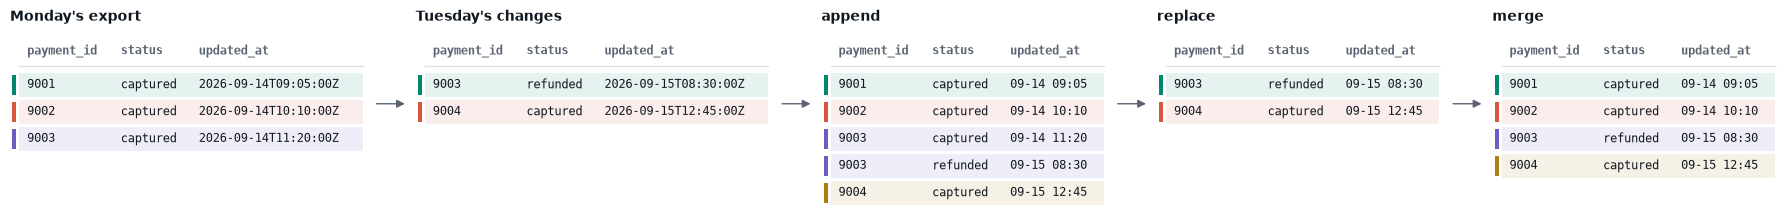

In [15]:
cols = "payment_id, status, updated_at"
V.table_steps([
    {"title": "Monday's export", "df": pd.DataFrame(provider(MON))[cols.split(", ")]},
    {"title": "Tuesday's changes", "df": pd.DataFrame(tuesday_changes)[cols.split(", ")]},
    {"title": "append", "df": sql(f"SELECT {cols} FROM raw.pay_append ORDER BY 1, 3")},
    {"title": "replace", "df": sql(f"SELECT {cols} FROM raw.pay_replace ORDER BY 1")},
    {"title": "merge", "df": sql(f"SELECT {cols} FROM raw.pay_merge ORDER BY 1")},
], color_by="payment_id")

🔍 `append` kept both versions of 9003 (the script's bug). `replace` kept only Tuesday's two rows: it is right only
when each run sends **everything**. `merge` has one row per payment, each at its latest version.

Qafila's store list is one such export, sent whole every night. On Tuesday, `DMM-01` has closed and is no longer
in it. With `replace`, the table always equals the latest export:

In [16]:
STORES_MON = [{"store_id": "RUH-04", "city": "Riyadh"}, {"store_id": "JED-03", "city": "Jeddah"},
              {"store_id": "DMM-01", "city": "Dammam"}]
STORES_TUE = [{"store_id": "RUH-04", "city": "Riyadh"}, {"store_id": "JED-03", "city": "Jeddah"}]

for export in [STORES_MON, STORES_TUE]:
    pipe.run(export, table_name="stores", write_disposition="replace")
sql("SELECT store_id, city FROM raw.stores ORDER BY store_id")

,store_id,city
0,JED-03,Jeddah
1,RUH-04,Riyadh


🔍 With `merge`, `DMM-01` would stay forever: a merge only touches the keys it receives, so a row that disappears
from the source never disappears from the table. Seeing **deletes** needs either the whole table (`replace`) or a
change feed that says "deleted" (CDC, Lab 1.4).

## 5 · Incremental loading: a cursor kept in state

Big tables can't be resent whole every night: we want only what changed. A **resource** is a generator with load
instructions on its decorator. The `incremental` argument is the cursor: dlt fills in `last_value` (the highest
`updated_at` loaded so far) before each run, and updates it after.

In [17]:
@dlt.resource(name="payments", primary_key="payment_id", write_disposition="merge")
def payments(day, updated_at=dlt.sources.incremental("updated_at", initial_value="2026-09-01T00:00:00Z")):
    print(f"  {day}: asking the provider for changes since {updated_at.last_value}")
    yield provider(day, since=updated_at.last_value)


for day in [MON, TUE]:
    pipe.run(payments(day))
sql("SELECT payment_id, status, updated_at FROM raw.payments ORDER BY 1")

  2026-09-14: asking the provider for changes since 2026-09-01T00:00:00Z


  2026-09-15: asking the provider for changes since 2026-09-14T11:20:00Z


,payment_id,status,updated_at
0,9001,captured,2026-09-14 09:05:00+00:00
1,9002,captured,2026-09-14 10:10:00+00:00
2,9003,refunded,2026-09-15 08:30:00+00:00
3,9004,captured,2026-09-15 12:45:00+00:00


🔍 Tuesday asked only for changes since Monday's last payment. The cursor lives in the pipeline's state:

In [18]:
pipe.state["sources"]["qafila_payments"]["resources"]["payments"]["incremental"]["updated_at"]

{'initial_value': '2026-09-01T00:00:00Z',
 'last_value': '2026-09-15T12:45:00Z',
 'unique_hashes': ['h2Y7BqMJBHoa'],
 'start_value': '2026-09-14T11:20:00Z'}

🤔 **Predict** · The scheduler retries Tuesday's run. What does it ask for, and how many rows does it load?

In [19]:
pipe.run(payments(TUE))
print(pipe.last_trace.last_normalize_info.row_counts)
U.check(sql("SELECT count(*) AS n FROM raw.payments").n[0] == 4, "still one row per payment")

  2026-09-15: asking the provider for changes since 2026-09-15T12:45:00Z


{}
✅ still one row per payment


🔍 It got payment 9004 back (`since` is inclusive), but dlt remembered loading that exact row and dropped it: the
run loaded **no** payments. Even without that, `merge` on `payment_id` would have made the retry harmless.

**Break it on purpose.** The state is in `pipe.working_dir` on this machine. Delete that folder, as if the job
moved to a new machine.

🤔 **Predict** · On Wednesday, does the fresh pipeline load Monday's payments again?

In [20]:
shutil.rmtree(pipe.working_dir)
pipe = dlt.pipeline(pipeline_name="qafila_payments", destination=dlt.destinations.duckdb(str(DB)),
                    dataset_name="raw", pipelines_dir=str(PIPELINES))
print("local state, before the run:", pipe.state.get("sources"))
pipe.run(payments(WED))
sql("SELECT payment_id, status, updated_at, _dlt_load_id FROM raw.payments ORDER BY 1")

local state, before the run: None


  2026-09-16: asking the provider for changes since 2026-09-15T12:45:00Z


,payment_id,status,updated_at,_dlt_load_id
0,9001,captured,2026-09-14 09:05:00+00:00,1792757574.948514
1,9002,captured,2026-09-14 10:10:00+00:00,1792757574.948514
2,9003,refunded,2026-09-15 08:30:00+00:00,1792757576.5382185
3,9004,captured,2026-09-15 12:45:00+00:00,1792757576.5382185
4,9005,captured,2026-09-16 09:15:00+00:00,1792757579.2814183


🔍 No. With no local state, dlt read it back from `raw._dlt_pipeline_state` and asked only for changes since Tuesday.
That's why the state is stored **in the destination, in the same load as the data**: the cursor can never be ahead
of the rows (data lost) or behind them (data loaded twice). It moves with the data, or not at all.

In [21]:
sql("SELECT version, pipeline_name, created_at, _dlt_load_id FROM raw._dlt_pipeline_state ORDER BY version")

,version,pipeline_name,created_at,_dlt_load_id
0,1,qafila_payments,2026-10-23 12:12:42.997042+00:00,1792757562.9479651
1,2,qafila_payments,2026-10-23 12:12:47.475009+00:00,1792757567.387461
2,3,qafila_payments,2026-10-23 12:12:55.035400+00:00,1792757574.948514
3,4,qafila_payments,2026-10-23 12:12:56.682009+00:00,1792757576.5382185
4,5,qafila_payments,2026-10-23 12:12:59.447719+00:00,1792757579.2814183


🎓 This is the answer to the cursor-in-a-file problem in §1. Lab 1.3's first checkpoint question asks it again.

## 6 · Break it on purpose: a late record slips past the cursor

➕ A cursor trusts that records arrive in `updated_at` order. Payment **9006** was made Wednesday at 08:50, but the
provider only exported it on Thursday.

🤔 **Predict** · Thursday's run asks for changes since Wednesday 09:15 (payment 9005). Does 9006 arrive?

In [22]:
pipe.run(payments(THU))
loaded = sql("SELECT payment_id, updated_at FROM raw.payments ORDER BY updated_at")
display(loaded)
U.check(9006 not in loaded.payment_id.tolist(), "9006 is missing, and nothing failed")

  2026-09-17: asking the provider for changes since 2026-09-16T09:15:00Z


,payment_id,updated_at
0,9001,2026-09-14 09:05:00+00:00
1,9002,2026-09-14 10:10:00+00:00
2,9003,2026-09-15 08:30:00+00:00
3,9004,2026-09-15 12:45:00+00:00
4,9005,2026-09-16 09:15:00+00:00
5,9007,2026-09-17 10:00:00+00:00


✅ 9006 is missing, and nothing failed


🔍 9006 is older than the cursor, so no run will ever ask for it. A **lag** makes each run re-read a window before
the cursor. The same resource with `lag=3600` asks for changes since an hour before `last_value`. Rows re-read in
that window are already loaded, and `merge` replaces them with themselves, so the overlap is safe.

In [23]:
@dlt.resource(name="payments_lagged", primary_key="payment_id", write_disposition="merge")
def payments_lagged(day, updated_at=dlt.sources.incremental("updated_at", initial_value="2026-09-01T00:00:00Z",
                                                            lag=3600)):
    print(f"  {day}: asking the provider for changes since {updated_at.last_value}")
    yield provider(day, since=updated_at.last_value)


for day in [MON, TUE, WED, THU]:
    pipe.run(payments_lagged(day))
sql("SELECT payment_id, count(*) AS n FROM raw.payments_lagged GROUP BY 1 ORDER BY 1")

  2026-09-14: asking the provider for changes since 2026-09-01T00:00:00Z


  2026-09-15: asking the provider for changes since 2026-09-14T10:20:00Z


  2026-09-16: asking the provider for changes since 2026-09-15T11:45:00Z


  2026-09-17: asking the provider for changes since 2026-09-16T08:15:00Z


,payment_id,n
0,9001,1
1,9002,1
2,9003,1
3,9004,1
4,9005,1
5,9006,1
6,9007,1


🔍 All seven payments, each once. But a lag only catches records up to an hour late. How late can a record be? Only
the source can tell you: ask the provider, or measure it.

## 7 · Schemas: inferred, evolved, nested, and frozen by a contract

On Wednesday the provider started sending `wallet_provider`. Our script crashed. What did dlt do?

In [24]:
sql("""SELECT column_name, data_type FROM information_schema.columns
       WHERE table_schema = 'raw' AND table_name = 'payments' ORDER BY ordinal_position""")

,column_name,data_type
0,payment_id,BIGINT
1,order_id,BIGINT
2,amount,DOUBLE
3,method,VARCHAR
4,status,VARCHAR
5,updated_at,TIMESTAMP WITH TIME ZONE
6,_dlt_load_id,VARCHAR
7,_dlt_id,VARCHAR
8,wallet_provider,VARCHAR


🔍 It **evolved** the table: a new column, `NULL` for the older rows. Every change is a new schema version in
`_dlt_version`, so you can see when it happened.

➕ APIs also send **nested** data. An order from the app's API:

In [25]:
ORDERS = [{"order_id": 106, "store_id": "JED-03", "customer": {"id": 5501, "city": "Jeddah"},
           "items": [{"sku": "TEA-01", "qty": 2}, {"sku": "DATES-1KG", "qty": 1}]}]
pipe.run(ORDERS, table_name="orders")
display(sql("SELECT * FROM raw.orders"))
sql("SELECT * FROM raw.orders__items")

,order_id,store_id,customer__id,customer__city,_dlt_load_id,_dlt_id
0,106,JED-03,5501,Jeddah,1792757589.837399,LfDe+PsqekYTqg


,sku,qty,_dlt_parent_id,_dlt_list_idx,_dlt_id
0,TEA-01,2,LfDe+PsqekYTqg,0,8tef/kY9YrPxsg
1,DATES-1KG,1,LfDe+PsqekYTqg,1,elq6RBXqSIZd9g


🔍 A nested object becomes columns (`customer__id`, `customer__city`). A list becomes a **child table**,
`orders__items`, one row per element, linked to its parent by `_dlt_parent_id` = the parent's `_dlt_id`.

➕ 🤔 **Predict** · A supplier sends Purchasing its prices. In week 38 their export switches to a decimal comma:
`"9,49"`. What happens to the `unit_cost` column?

In [26]:
PRICES_W37 = [{"sku": "TEA-01", "unit_cost": 9.49}, {"sku": "DATES-1KG", "unit_cost": 31.00}]
PRICES_W38 = [{"sku": "TEA-01", "unit_cost": "9,49"}, {"sku": "DATES-1KG", "unit_cost": "31,00"}]
for week in [PRICES_W37, PRICES_W38]:
    pipe.run(week, table_name="prices")
sql("SELECT sku, unit_cost, unit_cost__v_text, _dlt_load_id FROM raw.prices")

,sku,unit_cost,unit_cost__v_text,_dlt_load_id
0,TEA-01,9.49,NaN,1792757591.3073404
1,DATES-1KG,31.00,NaN,1792757591.3073404
2,TEA-01,NaN,"9,49",1792757592.4574971
3,DATES-1KG,NaN,"31,00",1792757592.4574971


🔍 dlt didn't fail and didn't guess: the text landed in a **variant column**, `unit_cost__v_text`. The bronze zone
has everything the supplier sent, but a report on `unit_cost` now silently misses week 38.

➕ When a table must not change without someone deciding it, declare a **schema contract**. Here new columns are
frozen, and a payment arrives with one:

In [27]:
from dlt.pipeline.exceptions import PipelineStepFailed

try:
    pipe.run([{"payment_id": 9008, "amount": 5.0, "card_country": "SA"}], table_name="payments",
             schema_contract={"columns": "freeze"})
except PipelineStepFailed as e:
    print("❌ failed in step:", e.step)
    print(re.search(r"Contract on .*?frozen\.", str(e)).group())
_ = pipe.abort_packages()   # throw away the package that failed, or the next run tries it again

❌ failed in step: normalize
Contract on `columns` with `contract_mode=freeze` is violated. Can't add table column `card_country` to table `payments` because `columns` are frozen.


🔍 The run failed in **normalize**, before anything reached the table. `{"data_type": "freeze"}` would have refused
week 38's `"9,49"` the same way.

Strict or tolerant is a choice per table. Bronze usually **tolerates**: new fields land, so nothing is lost, and
checks downstream catch the rest (Lab 2.4). Strict stops the pipeline and needs someone to answer the alert.

## 8 · From Python lists to a real API

➕ The real provider is an HTTP API: pages of 500 records, a cursor parameter `updated_since`, and a **429 Too Many
Requests** when you call too fast. `U.PaymentsAPI` is a local copy of it, the one Lab 1.3 uses. dlt's `RESTClient`
follows the pages and retries the 429s:

In [28]:
from dlt.sources.helpers.rest_client import RESTClient
from dlt.sources.helpers.rest_client.paginators import JSONLinkPaginator

U.ensure_data()
api = U.PaymentsAPI(page_size=500, rate_limit_every=2, clock="2026-09-15T00:00:00.000Z")
client = RESTClient(base_url=api.start(), paginator=JSONLinkPaginator(next_url_path="next"), data_selector="data")
pages = list(client.paginate("/payments", params={"updated_since": "2026-09-14T00:00:00.000Z"}))
print(f"{len(pages)} pages of {[len(p) for p in pages]} records | requests: {api.requests} | 429s retried: {api.throttled}")
api.stop()

2 pages of [500, 165] records | requests: 3 | 429s retried: 1


🔍 `JSONLinkPaginator(next_url_path="next")` reads the next page's URL from each response, and `data_selector` says
where the records are. The 429s were retried with backoff, without a line of our code. In Lab 1.3 you first write
that loop yourself, then put this client inside an incremental resource.

## 9 · Summary

| | |
|---|---|
| **It does** | paging and retries · write dispositions · incremental cursors with state in the destination · schema inference, evolution and contracts · load ids and a load log |
| **It doesn't** | see rows deleted at the source (CDC, Lab 1.4) · clean or model data (Polars, dbt: Day 2) · decide when to run (Dagster, Lab 4.1) |
| **In this course** | Lab 1.3 loads the payments API and the app database into a DuckDB `raw` schema, the bronze zone |
| **As a service** | Fivetran, Airbyte, AWS Glue, Azure Data Factory: the same jobs, hosted, with ready-made connectors |

**Cheat sheet**

| Code | Does |
|---|---|
| `dlt.pipeline(pipeline_name=..., destination=..., dataset_name=...)` | a named pipeline into a dataset |
| `pipe.run(data, table_name=..., write_disposition=..., primary_key=...)` | extract + normalize + load |
| `pipe.extract(...)`, `pipe.normalize()`, `pipe.load()` | the three steps one at a time |
| `write_disposition="append"` / `"replace"` / `"merge"` | events and logs / small tables sent whole / records that change (upsert on `primary_key`) |
| `@dlt.resource(name=..., primary_key=..., write_disposition="merge")` | a generator with load instructions |
| `dlt.sources.incremental("updated_at", initial_value=..., lag=...)` | a cursor kept in state |
| `schema_contract={"columns": "freeze"}` | fail instead of evolving; parts `tables`, `columns`, `data_type`; modes `evolve` (default), `freeze`, `discard_row`, `discard_value` |
| `pipe.state`, `raw._dlt_pipeline_state` | the state, locally and in the destination |
| `raw._dlt_loads`, `_dlt_load_id` | the load log, and the load of each row |
| `_dlt_id`, `_dlt_parent_id` | a row's id, and the parent row of a child-table row |
| `raw._dlt_version` | every version of the schema |
| `pipe.abort_packages()` | discard a package that failed |
| `RESTClient(base_url=..., paginator=..., data_selector=...)` | an HTTP client that pages and retries |
| `sql_table(credentials=..., table=..., incremental=...)`, `filesystem(...)` | ready-made sources for databases (SQLAlchemy) and files |

## Checkpoint

1. The script in §1 broke in four ways. Which dlt feature answers each?
2. When is `replace` right, and why can't `merge` see that a store closed?
3. Where does dlt keep the cursor, and why there? What does a lag of one hour fix, and what does it still miss?
4. Week 38's `"9,49"`: is the variant column a feature or a trap? Who should find out, and when?

Next: [Lab 1.3 · Ingest Qafila with dlt](../D1_3_ingestion_dlt.ipynb). Docs:
[pipeline](https://dlthub.com/docs/general-usage/pipeline) ·
[write dispositions](https://dlthub.com/docs/general-usage/incremental-loading) ·
[incremental cursors](https://dlthub.com/docs/general-usage/incremental/cursor) ·
[schema evolution](https://dlthub.com/docs/general-usage/schema-evolution) ·
[schema contracts](https://dlthub.com/docs/general-usage/schema-contracts) ·
[REST client](https://dlthub.com/docs/general-usage/http/rest-client).

**What you built:** the dataset dlt built, with our tables, the child table and dlt's own `_dlt_*` tables.

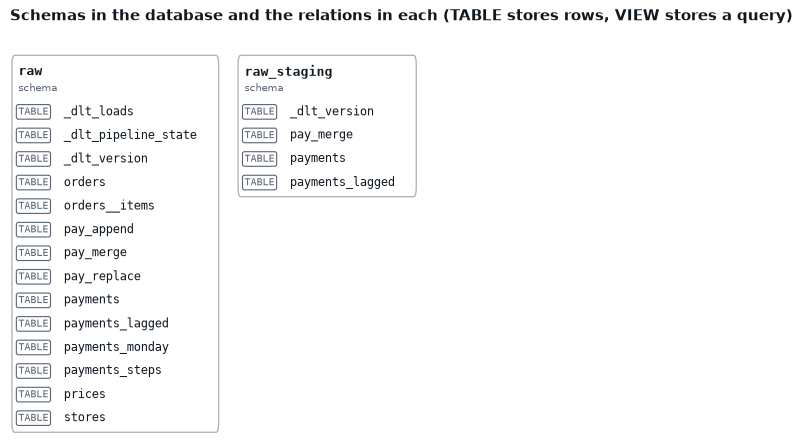

In [29]:
V.database_map(sql("SELECT table_schema, table_name, table_type FROM information_schema.tables"))

🔍 `raw_staging` is where `merge` lands each run's rows before it upserts them into `raw`: dlt creates it only for
merged tables (`pay_merge`, `payments`, `payments_lagged`). `append` and `replace` write straight into `raw`.